# Student Academic Success Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 43

# biar semua kolom ga kepotong
pd.set_option("display.max_columns", None)

# EDA

In [2]:
train_data = pd.read_csv("data/train.csv")
test_data = pd.read_csv("data/test.csv")

print(f"Train data shape: {train_data.shape}")
print(f"Test data shape: {test_data.shape}")

Train data shape: (3096, 38)
Test data shape: (1328, 37)


In [3]:
train_data.head(3)

,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,3743,1,17,1,9670,1,1,118.0,1,19,38,7,9,113.5,1,0,0,1,0,1,19,0,0,6,9,5,13.500000,0,0,6,6,6,14.000000,0,12.4,0.5,1.79,Graduate
1,3540,1,1,1,9070,1,1,139.0,1,1,19,3,9,134.9,1,0,0,1,1,0,20,0,0,6,7,6,13.666667,0,0,6,7,6,12.166667,1,16.2,0.3,-0.92,Graduate
2,1118,1,1,1,9500,1,1,138.0,1,38,19,9,5,144.3,0,0,0,1,0,0,20,0,0,7,9,6,12.700000,0,0,8,8,7,13.571429,0,13.9,-0.3,0.79,Graduate


In [4]:
test_data.head(3)

,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,2701,1,1,1,171,1,1,127.0,1,1,1,4,3,126.3,1,0,1,1,1,0,21,0,0,0,0,0,0.0,0,0,0,0,0,0.0,0,16.2,0.3,-0.92
1,1142,1,17,6,9147,1,1,121.0,1,19,38,7,9,123.8,0,0,0,1,0,1,19,0,0,5,5,5,12.4,0,0,5,8,3,11.0,0,12.7,3.7,-1.70
2,3538,1,39,2,9147,1,19,133.1,1,38,19,4,10,116.3,0,0,0,0,1,0,32,0,0,5,5,0,0.0,0,0,5,9,0,0.0,0,10.8,1.4,1.74


In [5]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3096 entries, 0 to 3095
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Student_ID                                      3096 non-null   int64  
 1   Marital status                                  3096 non-null   int64  
 2   Application mode                                3096 non-null   int64  
 3   Application order                               3096 non-null   int64  
 4   Course                                          3096 non-null   int64  
 5   Daytime/evening attendance	                     3096 non-null   int64  
 6   Previous qualification                          3096 non-null   int64  
 7   Previous qualification (grade)                  3096 non-null   float64
 8   Nacionality                                     3096 non-null   int64  
 9   Mother's qualification                          3096

Hasil Cek Data:
1. tidak ada data yang null
2. ada 2 kolom yang namanya bermasalah (Daytime/evening attendance\t dan Nacionality)

In [6]:
# rename kolom
train_data = train_data.rename(columns={"Nacionality": "Nationality"})
test_data = test_data.rename(columns={"Nacionality": "Nationality"})

train_data.columns = train_data.columns.str.strip()
test_data.columns = test_data.columns.str.strip()

display(train_data.head(3))
display(test_data.head(3))

,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,3743,1,17,1,9670,1,1,118.0,1,19,38,7,9,113.5,1,0,0,1,0,1,19,0,0,6,9,5,13.500000,0,0,6,6,6,14.000000,0,12.4,0.5,1.79,Graduate
1,3540,1,1,1,9070,1,1,139.0,1,1,19,3,9,134.9,1,0,0,1,1,0,20,0,0,6,7,6,13.666667,0,0,6,7,6,12.166667,1,16.2,0.3,-0.92,Graduate
2,1118,1,1,1,9500,1,1,138.0,1,38,19,9,5,144.3,0,0,0,1,0,0,20,0,0,7,9,6,12.700000,0,0,8,8,7,13.571429,0,13.9,-0.3,0.79,Graduate


,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,2701,1,1,1,171,1,1,127.0,1,1,1,4,3,126.3,1,0,1,1,1,0,21,0,0,0,0,0,0.0,0,0,0,0,0,0.0,0,16.2,0.3,-0.92
1,1142,1,17,6,9147,1,1,121.0,1,19,38,7,9,123.8,0,0,0,1,0,1,19,0,0,5,5,5,12.4,0,0,5,8,3,11.0,0,12.7,3.7,-1.70
2,3538,1,39,2,9147,1,19,133.1,1,38,19,4,10,116.3,0,0,0,0,1,0,32,0,0,5,5,0,0.0,0,0,5,9,0,0.0,0,10.8,1.4,1.74


In [7]:
train_data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Student_ID,3096.0,2201.76,1275.01,1.00,1102.75,2212.00,3303.75,4424.00
Marital status,3096.0,1.17,0.57,1.00,1.00,1.00,1.00,6.00
Application mode,3096.0,18.37,17.46,1.00,1.00,17.00,39.00,57.00
Application order,3096.0,1.72,1.29,0.00,1.00,1.00,2.00,9.00
Course,3096.0,8832.33,2116.52,33.00,9085.00,9238.00,9556.00,9991.00
Daytime/evening attendance,3096.0,0.89,0.31,0.00,1.00,1.00,1.00,1.00
Previous qualification,3096.0,4.67,10.39,1.00,1.00,1.00,1.00,43.00
Previous qualification (grade),3096.0,132.76,13.14,95.00,125.00,133.10,140.00,190.00
Nationality,3096.0,1.80,6.78,1.00,1.00,1.00,1.00,108.00
Mother's qualification,3096.0,19.36,15.57,1.00,2.00,19.00,37.00,44.00


Hasil Describe
1. ada outlier pada age
2. skala data berbeda beda ada yang ratusan ada yang satuan

In [8]:
pd.DataFrame({
    "jumlah_unique": train_data.nunique(),
    "dtype": train_data.dtypes
}).sort_values("jumlah_unique")

,jumlah_unique,dtype
Gender,2,int64
International,2,int64
Scholarship holder,2,int64
Tuition fees up to date,2,int64
Debtor,2,int64
Daytime/evening attendance,2,int64
Educational special needs,2,int64
Displaced,2,int64
Target,3,str
Marital status,6,int64


kolom dengan tipe kategori
- Marital status
- Application order
- Previous qualification
- Course
- Nationality
- Application mode
- Mother's qualification
- Mother's occupation
- Father's qualification
- Father's occupation

kolom dengan tipe biner
- Gender
- International
- Scholarship holder
- Tuition fees up to date
- Debtor
- Daytime/evening attendance
- Educational special needs
- Displaced

Target
Graduate    1546
Dropout      994
Enrolled     556
Name: count, dtype: int64


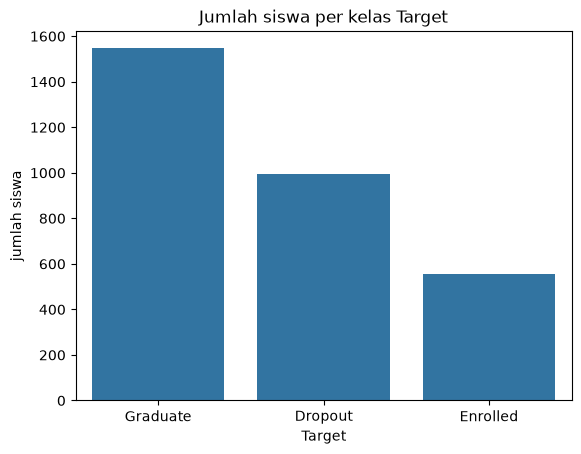

In [9]:
urutan_kelas = train_data["Target"].value_counts().index

print(train_data["Target"].value_counts())

sns.countplot(data=train_data, x="Target", order=urutan_kelas)
plt.title("Jumlah siswa per kelas Target")
plt.ylabel("jumlah siswa")
plt.show()

Distribusi antar target tidak merata dimana enrolled 1/3 dari graduate sehingga kita perlu memilih cara evaluasi model menggunakan F1 tidak bisa menggunakan akurasi

In [10]:
# cek apakah ada duplicate
print("duplikat (semua kolom):", train_data.duplicated().sum())
print("duplikat (tanpa Student_ID):", train_data.drop(columns="Student_ID").duplicated().sum())

duplikat (semua kolom): 0
duplikat (tanpa Student_ID): 0


In [11]:
var_desc = pd.read_csv("data/variables_description.csv")

with pd.option_context("display.max_colwidth", None):
    # nanti ubah aja index nya kalo mau ngecek deskripsi kolom
    display(var_desc[:5])


,name,description
0,Marital Status,1 - single 2 - married 3 - widower 4 - divorced 5 - facto union 6 - legally separated
1,Application mode,"1 - 1st phase - general contingent 2 - Ordinance No. 612/93 5 - 1st phase - special contingent (Azores Island) 7 - Holders of other higher courses 10 - Ordinance No. 854-B/99 15 - International student (bachelor) 16 - 1st phase - special contingent (Madeira Island) 17 - 2nd phase - general contingent 18 - 3rd phase - general contingent 26 - Ordinance No. 533-A/99, item b2) (Different Plan) 27 - Ordinance No. 533-A/99, item b3 (Other Institution) 39 - Over 23 years old 42 - Transfer 43 - Change of course 44 - Technological specialization diploma holders 51 - Change of institution/course 53 - Short cycle diploma holders 57 - Change of institution/course (International)"
2,Application order,Application order (between 0 - first choice; and 9 last choice)
3,Course,33 - Biofuel Production Technologies 171 - Animation and Multimedia Design 8014 - Social Service (evening attendance) 9003 - Agronomy 9070 - Communication Design 9085 - Veterinary Nursing 9119 - Informatics Engineering 9130 - Equinculture 9147 - Management 9238 - Social Service 9254 - Tourism 9500 - Nursing 9556 - Oral Hygiene 9670 - Advertising and Marketing Management 9773 - Journalism and Communication 9853 - Basic Education 9991 - Management (evening attendance)
4,Daytime/evening attendance,1 - daytime 0 - evening


In [12]:
kolom_data = set(train_data.columns)
kolom_deskripsi = set(var_desc["name"])

print("ada di data, tidak ada di deskripsi:", sorted(kolom_data - kolom_deskripsi))
print("ada di deskripsi, tidak ada di data:", sorted(kolom_deskripsi - kolom_data))

ada di data, tidak ada di deskripsi: ['Marital status', 'Nationality', 'Student_ID']
ada di deskripsi, tidak ada di data: ['Marital Status', 'Nacionality']


Kolom data dan deskripsi sudah sesuai, selisih minor dapat diabaikan

In [13]:
kolom_kategori = [
    "Marital status", "Application order", "Previous qualification", "Course",
    "Nationality", "Application mode", "Mother's qualification",
    "Mother's occupation", "Father's qualification", "Father's occupation",
]

kolom_biner = [
    "Gender", "International", "Scholarship holder", "Tuition fees up to date",
    "Debtor", "Daytime/evening attendance", "Educational special needs", "Displaced",
]

kolom_numerik = [
    c for c in train_data.columns
    if c not in kolom_kategori + kolom_biner + ["Student_ID", "Target"]
]

print("kategori:", len(kolom_kategori), "| biner:", len(kolom_biner), "| numerik:", len(kolom_numerik))

kategori: 10 | biner: 8 | numerik: 18


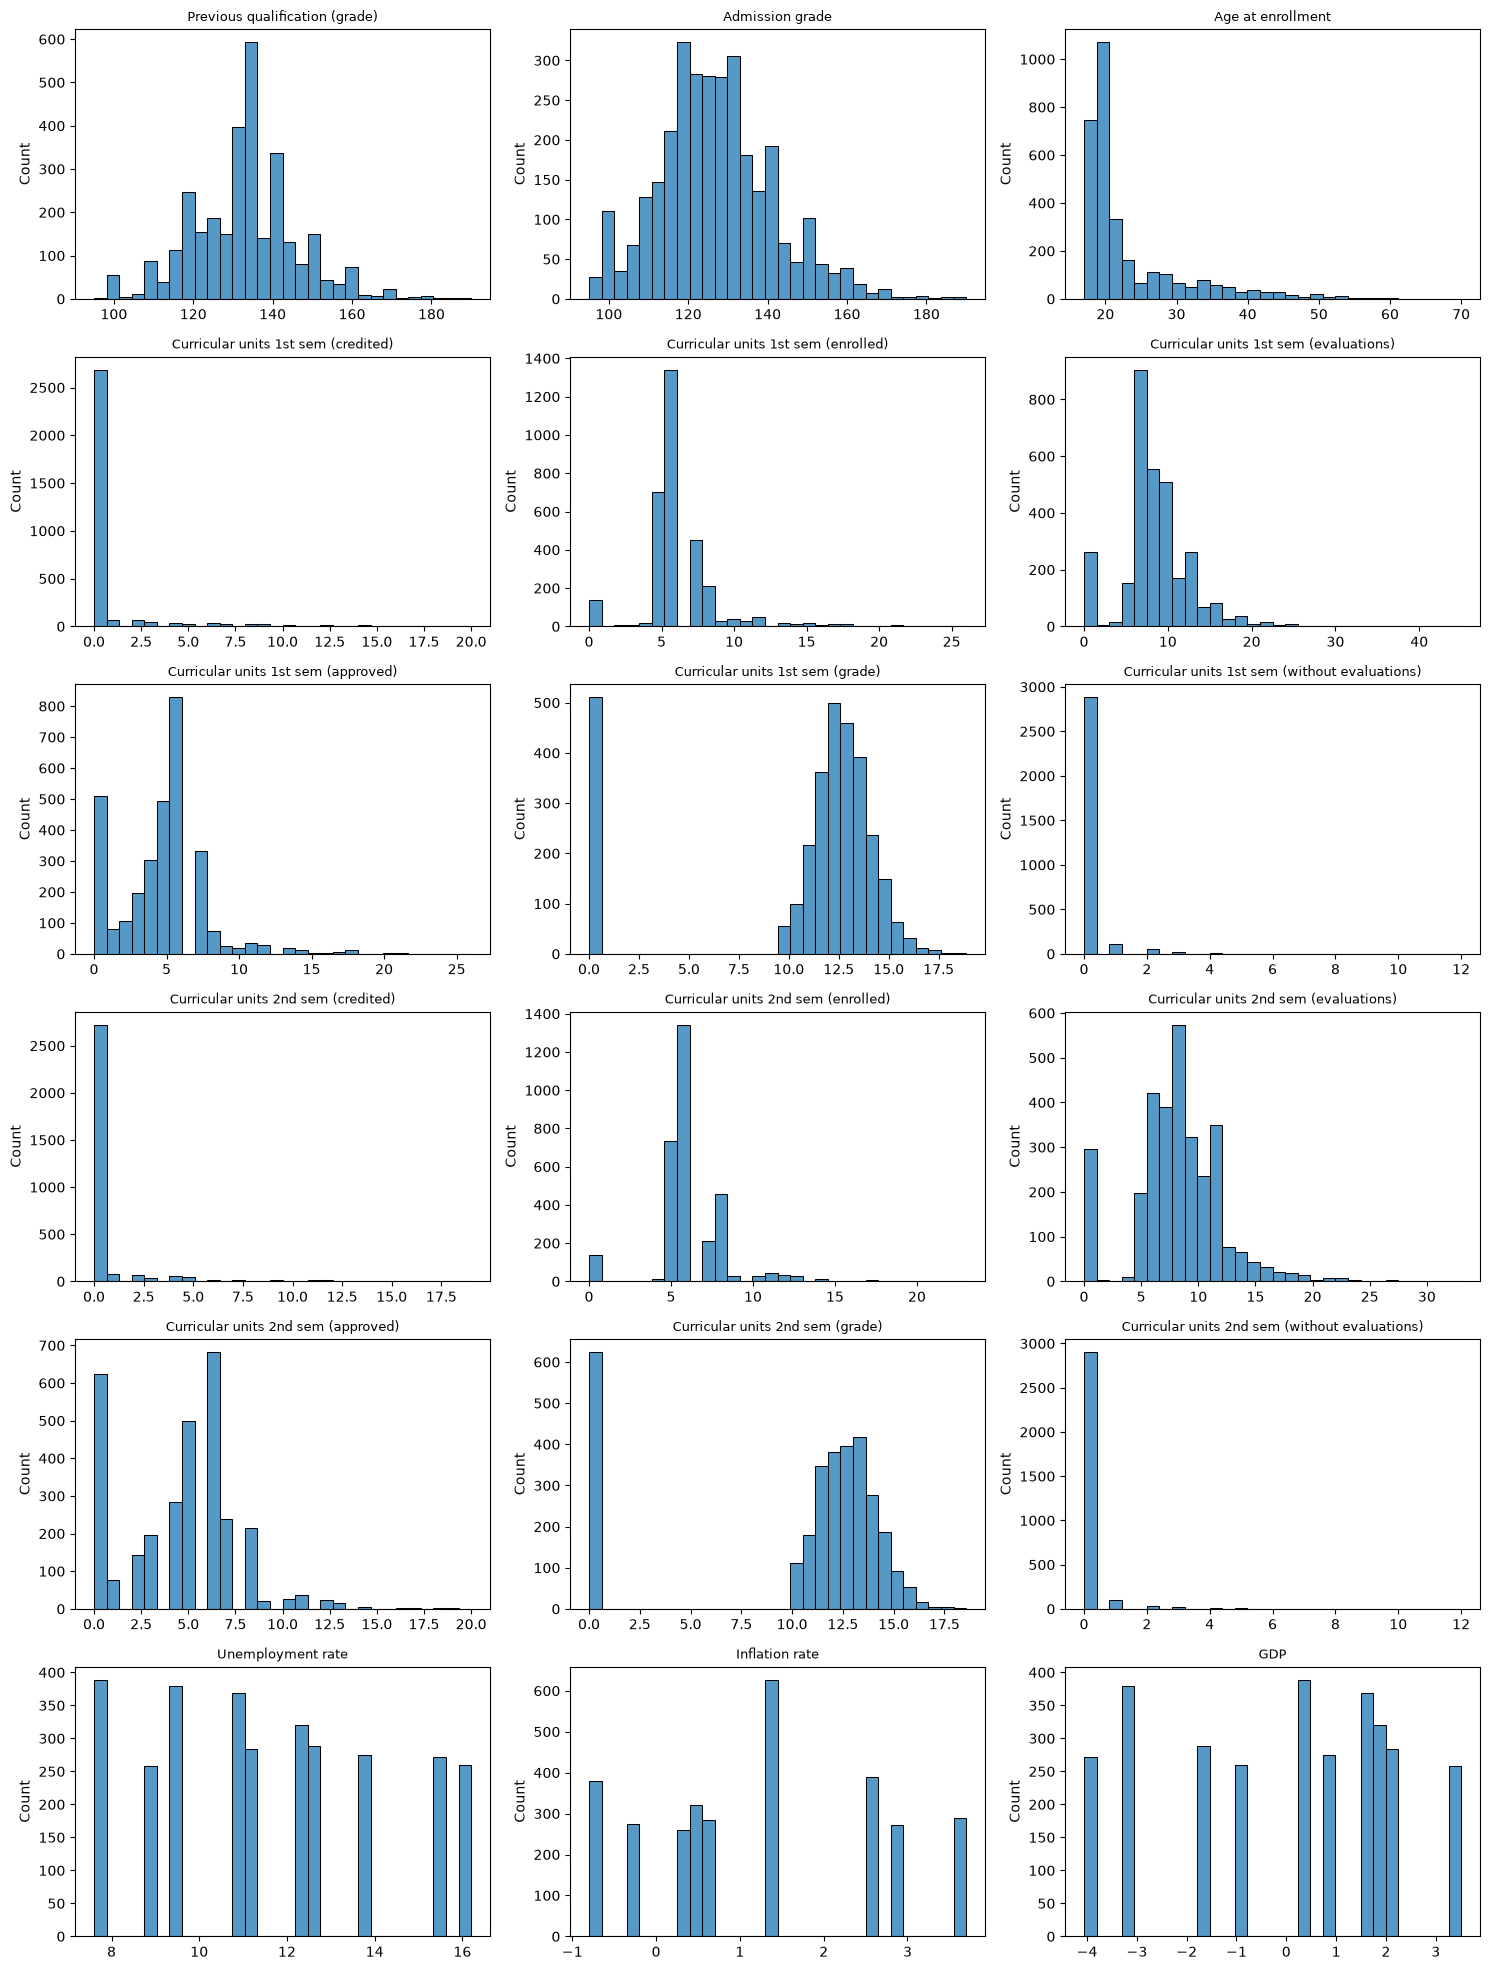

In [14]:
n_baris = len(kolom_numerik) // 3

fig, axes = plt.subplots(n_baris, 3, figsize=(15, 3.3 * n_baris))

for ax, kol in zip(axes.flat, kolom_numerik):
    sns.histplot(train_data[kol], bins=30, ax=ax)
    ax.set_title(kol, fontsize=9)
    ax.set_xlabel("")
    
plt.tight_layout()
plt.show()

In [15]:
for sem in ["1st", "2nd"]:
    prefix = f"Curricular units {sem} sem"
    grade_nol = train_data[f"{prefix} (grade)"] == 0
    print(f"[{sem} sem] jumlah baris dengan grade = 0:", grade_nol.sum())
    for c in ["enrolled", "evaluations", "approved"]:
        print(f"{c}", (train_data.loc[grade_nol, f"{prefix} ({c})"] == 0).sum())


[1st sem] jumlah baris dengan grade = 0: 511
enrolled 137
evaluations 261
approved 511
[2nd sem] jumlah baris dengan grade = 0: 624
enrolled 137
evaluations 293
approved 624


Insight
- Histogram grade punya bar tinggi di 0, lalu celah kosong dari 0 sampai sekitar 10 sebelum sebaran nilai sebenarnya.

- Jumlah baris grade = 0 ada sebanyak 511 (semester 1) dan 624 (semester 2). Angka ini sama persis dengan jumlah baris approved = 0, dan tidak ada baris approved = 0 yang gradenya bukan 0. Jadi kalau tidak ada mata kuliah yang lulus, grade pasti 0. Disimpulkan 0 di sini kemungkinan bukan nilai nol sungguhan, melainkan "tidak ada nilai".

- Dari baris grade = 0, hanya 137 yang enrolled = 0 (di kedua semester). Jadi sebagian besar terdaftar di mata kuliah tapi tidak lulus satu pun.

- Dari baris grade = 0, hanya 261 (semester 1) dan 293 (semester 2) yang evaluations = 0. Jadi sisanya ikut evaluasi tapi tidak lulus.


In [16]:
for sem in ["1st", "2nd"]:
    prefix = f"Curricular units {sem} sem"
    enrolled_nol = train_data[f"{prefix} (enrolled)"] == 0
    grade_nol = train_data[f"{prefix} (grade)"] == 0
    print(f"[{sem} sem] enrolled = 0: {enrolled_nol.sum()} | enrolled = 0 & grade = 0: {(enrolled_nol & grade_nol).sum()} | grade = 0 & enrolled > 0: {(grade_nol & ~enrolled_nol).sum()}")

enrolled_nol_1 = train_data["Curricular units 1st sem (enrolled)"] == 0
enrolled_nol_2 = train_data["Curricular units 2nd sem (enrolled)"] == 0
print("enrolled = 0 di kedua semester sekaligus:", (enrolled_nol_1 & enrolled_nol_2).sum())

[1st sem] enrolled = 0: 137 | enrolled = 0 & grade = 0: 137 | grade = 0 & enrolled > 0: 374
[2nd sem] enrolled = 0: 137 | enrolled = 0 & grade = 0: 137 | grade = 0 & enrolled > 0: 487
enrolled = 0 di kedua semester sekaligus: 137


In [17]:
pd.DataFrame({kol: train_data[kol].value_counts() for kol in kolom_biner}).T[[0, 1]]

,0,1
Gender,1999,1097
International,3024,72
Scholarship holder,2314,782
Tuition fees up to date,369,2727
Debtor,2755,341
Daytime/evening attendance,327,2769
Educational special needs,3059,37
Displaced,1398,1698


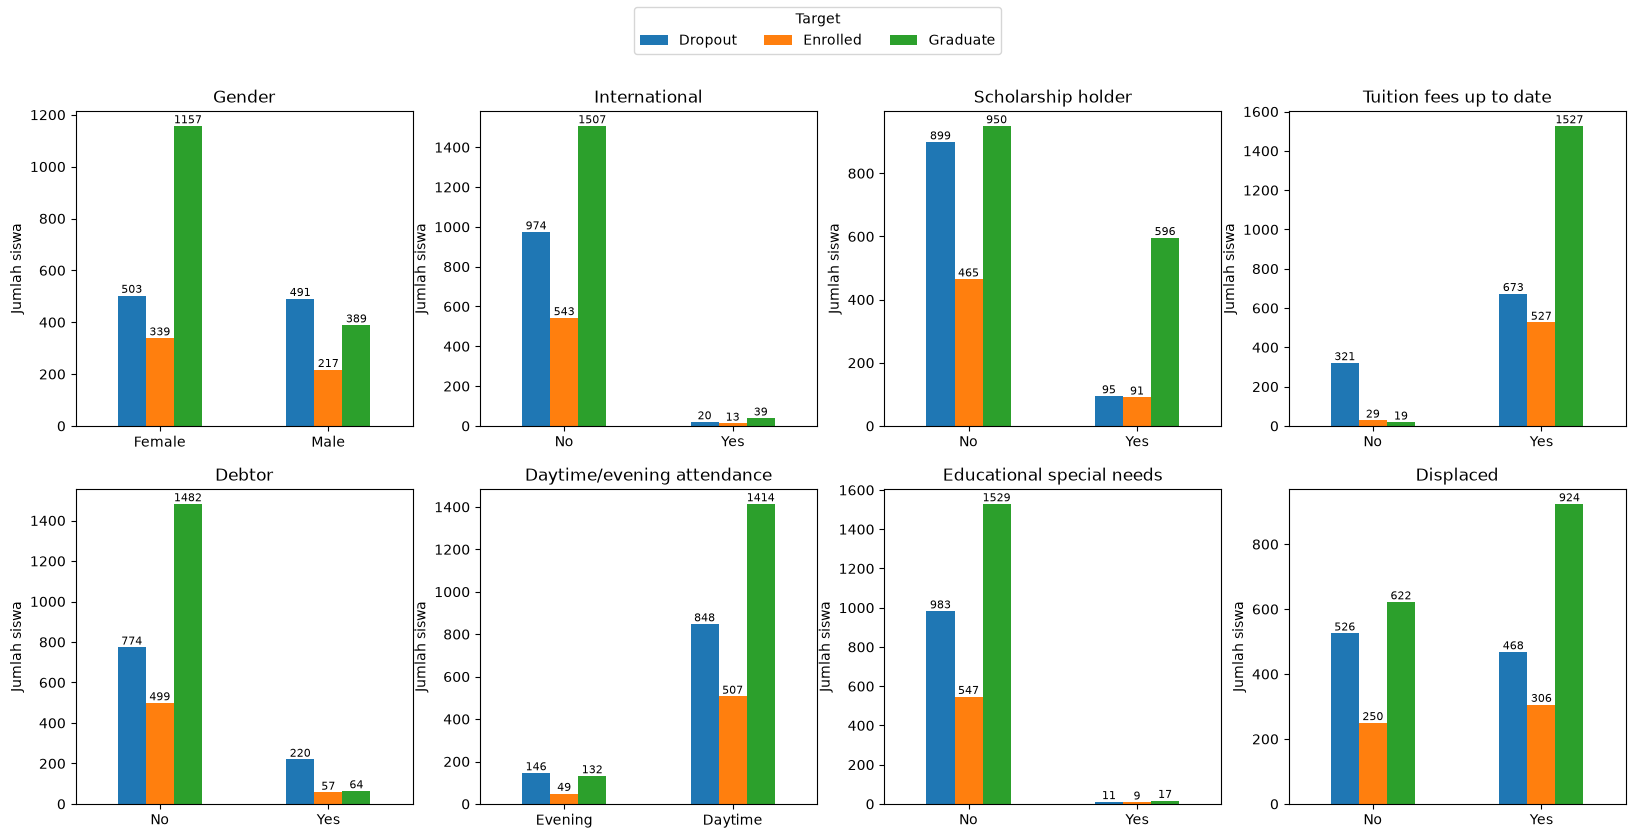

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

label_biner = {
    "Daytime/evening attendance": {0: "Evening", 1: "Daytime"},
    "Gender": {0: "Female", 1: "Male"},
}

label_default = {0: "No", 1: "Yes"} 


for ax, c in zip(axes.flatten(), kolom_biner):
    table = pd.crosstab(train_data[c], train_data["Target"])
    table = table.rename(index=label_biner.get(c, label_default))

    table.plot(kind="bar", ax=ax, rot=0, legend=False)

    for container in ax.containers:
        ax.bar_label(container, fontsize=8)

    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("Jumlah siswa")


handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, title="Target")

Insight
- Tuition fees up to date: pada kelompok No Dropout mendominasi. Pada kelompok Yes, mayoritas Graduate

- Debtor: pada kelompok Yes Dropout mendominasi

- Scholarship holder: pada kelompok Yes, Graduate mendominasi

- Gender: perempuan didominasi Graduate . Laki-laki lebih berimbang

- Daytime/evening attendance: pada Daytime, mayoritas graduate. Pada Evening, Dropout sedikit di atas Graduate.

- Internationaldan Educational special needs: kelompok Yes terlalu kecil untuk ditarik kesimpulan.


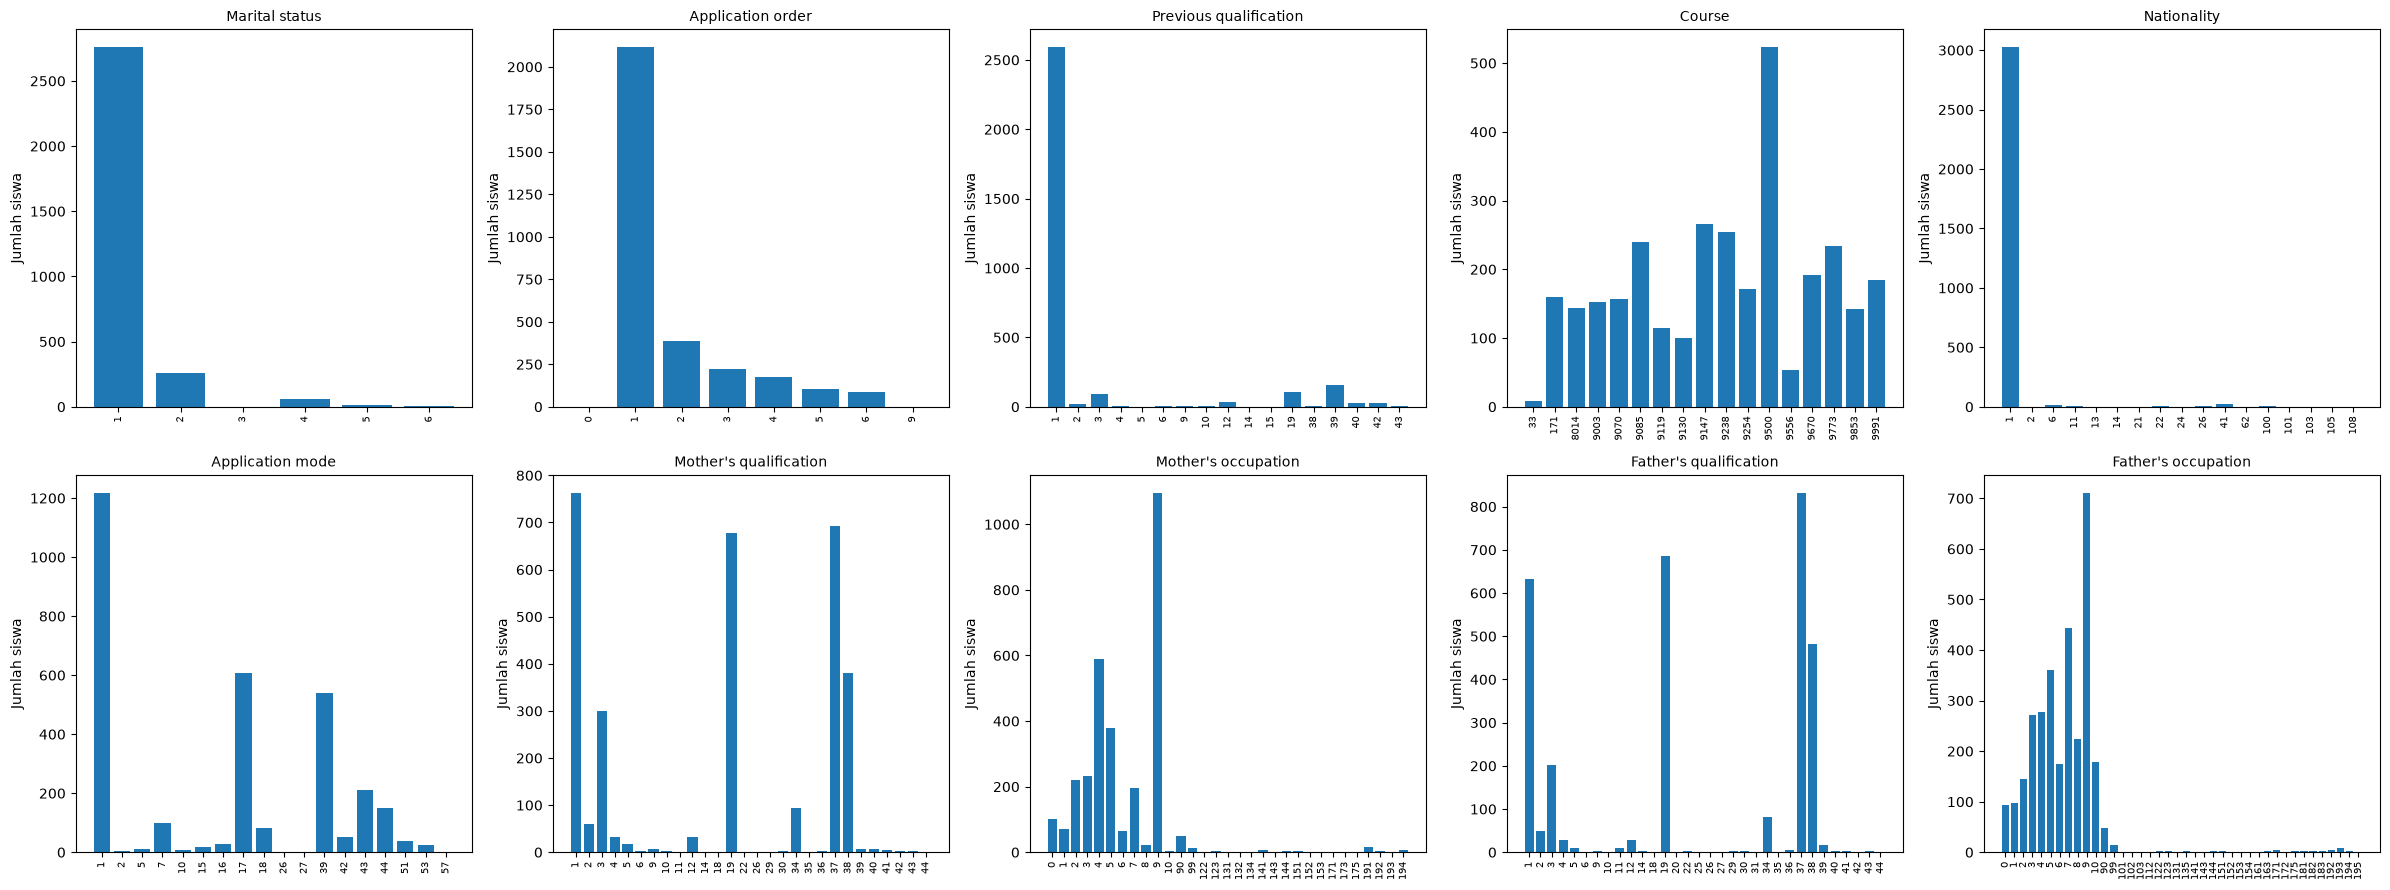

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(24, 9))

for ax, c in zip(axes.flatten(), kolom_kategori):
    jumlah = train_data[c].value_counts().sort_index()
    ax.bar(jumlah.index.astype(str), jumlah.values)
    ax.set_title(c, fontsize=10)
    ax.set_ylabel("Jumlah siswa")
    ax.tick_params(axis="x", rotation=90, labelsize=7)

plt.tight_layout()
plt.show()

Insight
- Marital status: kode 1 mendominasi
- Application order: kode 1 mendominasi, dan makin besar kodenya makin sedikit siswanya.
- Nationality: sangat tidak merata, sisanya tersebar di banyak kode yang masing-masing hanya segelintir siswa.
- Previous qualification: juga didominasi kode 1 (sekitar 2590 siswa).
- Mother's occupation dan Father's occupation: banyak kode dengan jumlah siswa sangat kecil, terutama kode bernilai besar di ujung kanan grafik. Kode jarang ini lebih baik digabung menjadi satu kelompok "lainnya" daripada dibuang, supaya tidak ada baris yang hilang


# Data Cleansing

Berdasarkan insight pada EDA berikut beberapa hal yang kami putuskan:

1. Pada kolom Curricular units 1st sem (grade) dan Curricular units 2nd sem (grade), nilai grade diubah menjadi NaN hanya untuk siswa yang enrolled = 0. alasannya mereka tidak mengambil mata kuliah sama sekali, jadi tidak ada nilai yang bisa dihitung. 

2. student id tidak termasuk kedalam feature

3. kategori dengan kode yang jarang akan digabung menjadi "lainnya" (kode yang diberikan -1)

In [20]:
# set grade menjadi nan pada siswa yang enrolled nya 0

for df in (train_data, test_data):
    for sem in ["1st", "2nd"]:
        prefix = f"Curricular units {sem} sem"
        df.loc[df[f"{prefix} (enrolled)"] == 0, f"{prefix} (grade)"] = np.nan

kolom_grade = ["Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
print("NaN di train:", train_data[kolom_grade].isna().sum().to_dict())
print("NaN di test :", test_data[kolom_grade].isna().sum().to_dict())

NaN di train: {'Curricular units 1st sem (grade)': 137, 'Curricular units 2nd sem (grade)': 137}
NaN di test : {'Curricular units 1st sem (grade)': 43, 'Curricular units 2nd sem (grade)': 43}


In [21]:
# drop target dan student id dari kolom feature
kolom_fitur = [c for c in train_data.columns if c not in ["Student_ID", "Target"]]

print("jumlah fitur:", len(kolom_fitur))
print("semua fitur ada di test:", set(kolom_fitur) <= set(test_data.columns))

jumlah fitur: 36
semua fitur ada di test: True


In [22]:
from sklearn.model_selection import train_test_split

X = train_data[kolom_fitur]
y = train_data["Target"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("train:", X_train.shape, "val:", X_val.shape)

train: (2476, 36) val: (620, 36)


In [23]:
threshold = [5, 10, 20, 50]
hasil = {}

for c in kolom_kategori:
    jumlah = X_train[c].value_counts()
    baris = {"total_kode": len(jumlah)}
    for t in threshold:
        baris[f"kode < {t} siswa"] = (jumlah < t).sum()
    hasil[c] = baris

pd.DataFrame(hasil).T


,total_kode,kode < 5 siswa,kode < 10 siswa,kode < 20 siswa,kode < 50 siswa
Marital status,5,1,1,2,2
Application order,8,2,2,2,2
Previous qualification,17,6,9,11,13
Course,17,0,1,1,2
Nationality,15,10,12,14,14
Application mode,18,4,6,7,11
Mother's qualification,27,15,17,18,21
Mother's occupation,29,13,17,18,20
Father's qualification,31,18,21,22,25
Father's occupation,39,25,26,27,28


In [24]:
threshold = 10

# application order di exclude karena berupa ordinal data
kolom = [c for c in kolom_kategori if c != "Application order"]

kode = {
    c: set(X_train[c].value_counts().loc[lambda s: s >= threshold].index) for c in kolom
}

def merge_kode(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for c in kode:
        df[c] = df[c].where(df[c].isin(kode[c]), -1) # kode yang datanya sedikit di merge jadi -1
    return df


X_train = merge_kode(X_train)
X_val = merge_kode(X_val)
test_feature = merge_kode(test_data[kolom_fitur])

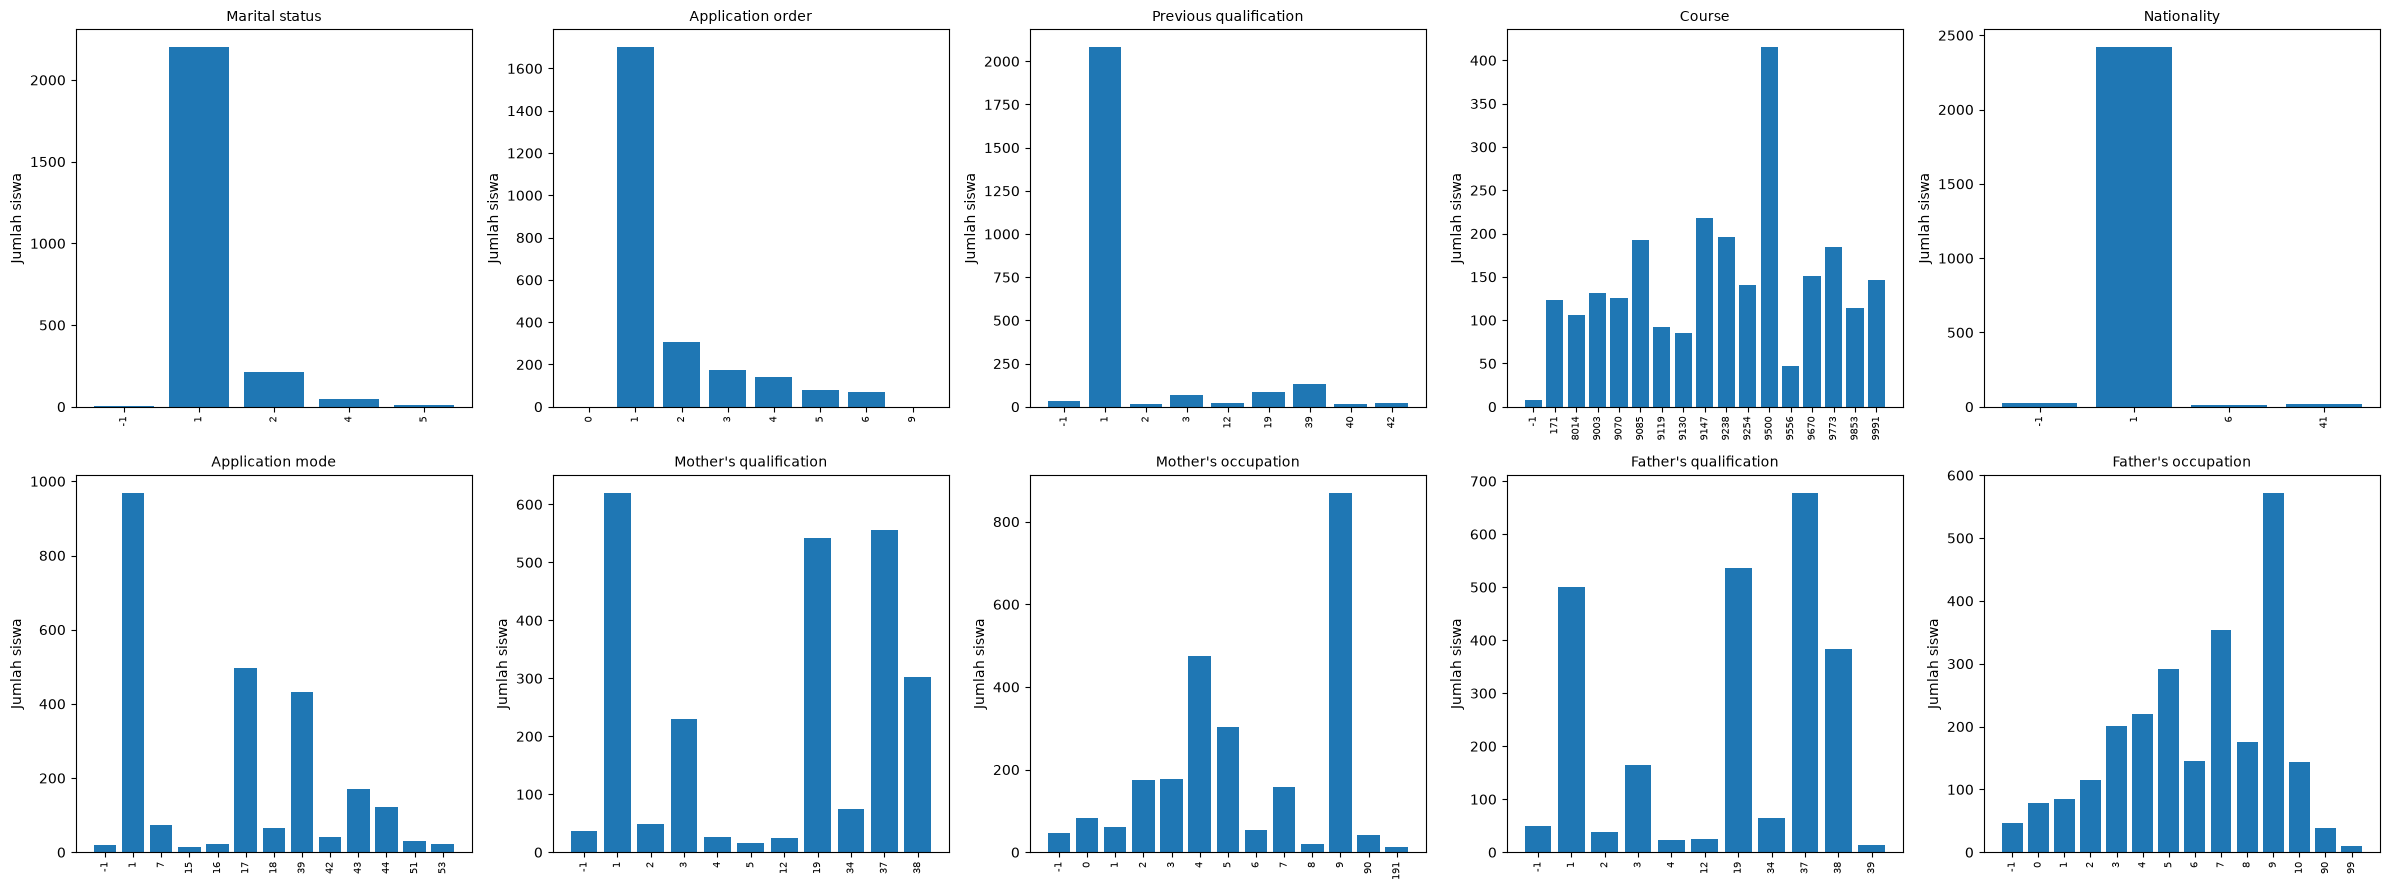

In [25]:
fig, axes = plt.subplots(2, 5, figsize=(24, 9))

for ax, c in zip(axes.flatten(), kolom_kategori):
    jumlah = X_train[c].value_counts().sort_index()
    ax.bar(jumlah.index.astype(str), jumlah.values)
    ax.set_title(c, fontsize=10)
    ax.set_ylabel("Jumlah siswa")
    ax.tick_params(axis="x", rotation=90, labelsize=7)

plt.tight_layout()
plt.show()

In [26]:
median_grade = X_train[kolom_grade].median()

X_train[kolom_grade] = X_train[kolom_grade].fillna(median_grade)
X_val[kolom_grade] = X_val[kolom_grade].fillna(median_grade)
test_feature[kolom_grade] = test_feature[kolom_grade].fillna(median_grade)

X_train[kolom_grade].head(3)

,Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
2210,12.928750,14.062500
2912,16.833333,16.666667
2355,12.908571,12.908571


Semua grade yang tadi kita set jadi NaN kita fill dengan median, alasannya karena median tidak terpengaruh nilai extreme dan setelah scalling akan berada di tengah sehingga tidak mendorong model prediksi ke arah tertentu. Selain itu kenapa ga dibiarin 0 adalah kita bisa bedakan mana yang memang 0 karena nilainya 0 sama siswa yang memang tidak mengambil mata kuliah

In [27]:
print("median grade dari train:", median_grade.to_dict())
print("shape :", X_train.shape, X_val.shape, test_feature.shape)
print("Jumlah NaN: train", X_train.isna().sum().sum(), "val", X_val.isna().sum().sum(), "test", test_feature.isna().sum().sum())

median grade dari train: {'Curricular units 1st sem (grade)': 12.4, 'Curricular units 2nd sem (grade)': 12.333333333333334}
shape : (2476, 36) (620, 36) (1328, 36)
Jumlah NaN: train 0 val 0 test 0


# Data Transformation

In [28]:
# Encoding Kolom Kategori
from sklearn.preprocessing import OneHotEncoder

kolom_nominal = [c for c in kolom_kategori if c != "Application order"]

encoder = OneHotEncoder(sparse_output=False)
encoder.fit(X_train[kolom_nominal])

def encode_kategori(df: pd.DataFrame) -> pd.DataFrame:
    one_hot = pd.DataFrame(
        encoder.transform(df[kolom_nominal]),
        columns=encoder.get_feature_names_out(kolom_nominal),
        index=df.index,
    )
    return pd.concat([df.drop(columns=kolom_nominal), one_hot], axis=1)


X_train_enc = encode_kategori(X_train)
X_val_enc = encode_kategori(X_val)
test_enc = encode_kategori(test_feature)

jumlah_one_hot = sum(len(k) for k in encoder.categories_)
print("shape:", X_train_enc.shape, X_val_enc.shape, test_enc.shape)
print("kolom one-hot:", jumlah_one_hot)

X_train_enc.head(3)

shape: (2476, 124) (620, 124) (1328, 124)
kolom one-hot: 97


,Application order,Daytime/evening attendance,Previous qualification (grade),Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Marital status_-1,Marital status_1,Marital status_2,Marital status_4,Marital status_5,Previous qualification_-1,Previous qualification_1,Previous qualification_2,Previous qualification_3,Previous qualification_12,Previous qualification_19,Previous qualification_39,Previous qualification_40,Previous qualification_42,Course_-1,Course_171,Course_8014,Course_9003,Course_9070,Course_9085,Course_9119,Course_9130,Course_9147,Course_9238,Course_9254,Course_9500,Course_9556,Course_9670,Course_9773,Course_9853,Course_9991,Nationality_-1,Nationality_1,Nationality_6,Nationality_41,Application mode_-1,Application mode_1,Application mode_7,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Application mode_39,Application mode_42,Application mode_43,Application mode_44,Application mode_51,Application mode_53,Mother's qualification_-1,Mother's qualification_1,Mother's qualification_2,Mother's qualification_3,Mother's qualification_4,Mother's qualification_5,Mother's qualification_12,Mother's qualification_19,Mother's qualification_34,Mother's qualification_37,Mother's qualification_38,Mother's occupation_-1,Mother's occupation_0,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_90,Mother's occupation_191,Father's qualification_-1,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_12,Father's qualification_19,Father's qualification_34,Father's qualification_37,Father's qualification_38,Father's qualification_39,Father's occupation_-1,Father's occupation_0,Father's occupation_1,Father's occupation_2,Father's occupation_3,Father's occupation_4,Father's occupation_5,Father's occupation_6,Father's occupation_7,Father's occupation_8,Father's occupation_9,Father's occupation_10,Father's occupation_90,Father's occupation_99
2210,2,1,140.0,129.9,1,0,0,1,0,0,18,0,0,7,8,7,12.928750,0,0,8,8,8,14.062500,0,15.5,2.8,-4.06,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2912,4,1,124.0,137.0,1,0,0,1,1,0,20,0,0,6,6,6,16.833333,0,0,6,6,6,16.666667,0,8.9,1.4,3.51,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2355,3,1,144.0,128.0,1,0,0,1,0,1,18,0,0,8,11,7,12.908571,0,0,8,11,7,12.908571,0,10.8,1.4,1.74,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.

In [29]:
# Scaling Data Numerik
from sklearn.preprocessing import StandardScaler

kolom_scale = kolom_numerik + ["Application order"]

scaler = StandardScaler()
scaler.fit(X_train_enc[kolom_scale])

X_train_sc = X_train_enc.copy()
X_train_sc[kolom_scale] = scaler.transform(X_train_sc[kolom_scale])

X_val_sc = X_val_enc.copy()
X_val_sc[kolom_scale] = scaler.transform(X_val_sc[kolom_scale])

test_sc = test_enc.copy()
test_sc[kolom_scale] = scaler.transform(test_sc[kolom_scale])

X_train_sc.head(3)


,Application order,Daytime/evening attendance,Previous qualification (grade),Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Marital status_-1,Marital status_1,Marital status_2,Marital status_4,Marital status_5,Previous qualification_-1,Previous qualification_1,Previous qualification_2,Previous qualification_3,Previous qualification_12,Previous qualification_19,Previous qualification_39,Previous qualification_40,Previous qualification_42,Course_-1,Course_171,Course_8014,Course_9003,Course_9070,Course_9085,Course_9119,Course_9130,Course_9147,Course_9238,Course_9254,Course_9500,Course_9556,Course_9670,Course_9773,Course_9853,Course_9991,Nationality_-1,Nationality_1,Nationality_6,Nationality_41,Application mode_-1,Application mode_1,Application mode_7,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Application mode_39,Application mode_42,Application mode_43,Application mode_44,Application mode_51,Application mode_53,Mother's qualification_-1,Mother's qualification_1,Mother's qualification_2,Mother's qualification_3,Mother's qualification_4,Mother's qualification_5,Mother's qualification_12,Mother's qualification_19,Mother's qualification_34,Mother's qualification_37,Mother's qualification_38,Mother's occupation_-1,Mother's occupation_0,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_90,Mother's occupation_191,Father's qualification_-1,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_12,Father's qualification_19,Father's qualification_34,Father's qualification_37,Father's qualification_38,Father's qualification_39,Father's occupation_-1,Father's occupation_0,Father's occupation_1,Father's occupation_2,Father's occupation_3,Father's occupation_4,Father's occupation_5,Father's occupation_6,Father's occupation_7,Father's occupation_8,Father's occupation_9,Father's occupation_10,Father's occupation_90,Father's occupation_99
2210,0.222330,1,0.549381,0.199685,1,0,0,1,0,0,-0.685364,0,-0.301545,0.307549,-0.061445,0.752145,0.403203,-0.219131,-0.279205,0.825127,-0.013244,1.205676,0.697092,-0.201533,1.451042,1.133584,-1.786868,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2912,1.766477,1,-0.664384,0.689784,1,0,0,1,1,0,-0.424092,0,-0.301545,-0.097931,-0.547512,0.424792,1.317309,-0.219131,-0.279205,-0.087137,-0.517739,0.539993,1.238907,-0.201533,-1.022421,0.125385,1.553867,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2355,0.994403,1,0.852822,0.068532,1,0,0,1,0,1,-0.685364,0,-0.301545,0.713028,0.667655,0.752145,0.398479,-0.219131

In [30]:
# Cek korelasi pada data train
corr = X_train_sc[kolom_scale].corr(method="spearman")

matriks = np.triu(np.ones(corr.shape, dtype=bool), k=1)

pair = corr.where(matriks).stack().rename("korelasi").reset_index()

pair.columns = ["fitur 1", "fitur 2", "korelasi"]

pair  = pair[pair["korelasi"].abs() >= 0.7].sort_values("korelasi", key=abs)

pair.round(3)

,fitur 1,fitur 2,korelasi
124,Curricular units 1st sem (approved),Curricular units 2nd sem (enrolled),0.714
82,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.717
146,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.719
126,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.886
66,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.910
86,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.960


Dengan batas korelasi Spearman ≥ 0.7 pada data train, ada 6 pasangan kolom yang berkorelasi tinggi, dan semuanya berasal dari kelompok Curricular units. 

Tiga yang tertinggi adalah pasangan semester 1 dan 2 untuk kolom yang sama: enrolled, credited, dan approved. Tiga lainnya adalah approved semester 1 dengan enrolled semester 2, enrolled semester 1 dengan approved semester 1, dan grade semester 1 dengan grade semester 2. 

Artinya siswa yang mengambil atau meluluskan banyak mata kuliah di satu semester cenderung melakukan hal yang sama di semester lain. Korelasi tinggi belum cukup alasan untuk membuang kolom, jadi kita lihat dulu hubungan tiap kolom dengan Target.


In [31]:
from sklearn.feature_selection import mutual_info_classif

fitur = X_train.columns.tolist()
fitur_diskrit = [c in kolom_kategori + kolom_biner for c in fitur]

mi = mutual_info_classif(X_train, y_train, discrete_features=fitur_diskrit, random_state=RANDOM_STATE)

skor_mi = pd.Series(mi, index=fitur).sort_values(ascending=False)

skor_mi.round(3)


Curricular units 2nd sem (approved)               0.305
Curricular units 2nd sem (grade)                  0.253
Curricular units 1st sem (approved)               0.244
Curricular units 1st sem (grade)                  0.211
Tuition fees up to date                           0.099
Curricular units 2nd sem (evaluations)            0.080
Course                                            0.068
Application mode                                  0.064
Curricular units 1st sem (evaluations)            0.064
Age at enrollment                                 0.060
Scholarship holder                                0.055
Curricular units 2nd sem (enrolled)               0.053
Previous qualification (grade)                    0.044
Curricular units 1st sem (enrolled)               0.044
Admission grade                                   0.043
Debtor                                            0.031
Mother's occupation                               0.029
Gender                                          

kandidat untuk di drop adalah
- Educational special needs
- International
- Curricular units 1st sem (credited)
- Curricular units 2nd sem (credited)
- Nationality
- Curricular units 2nd sem (without evaluations)

In [32]:
kolom_drop = [
    "Educational special needs",
    "International",
    "Nationality",
    "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (without evaluations)",
]

cleaned = [
    c for c in X_train_sc.columns if c in kolom_drop or any(c.startswith(f"{k}_") for k in kolom_drop)
]

X_train_final = X_train_sc.drop(columns=cleaned)
X_val_final = X_val_sc.drop(columns=cleaned)
test_final = test_sc.drop(columns=cleaned)

print("kolom dibuang:", len(cleaned))
print("shape:", X_train_final.shape, X_val_final.shape, test_final.shape)


kolom dibuang: 9
shape: (2476, 115) (620, 115) (1328, 115)


In [33]:
def handle_imbalance(X: pd.DataFrame, y: pd.Series, random_state: int) -> tuple[pd.DataFrame, pd.Series]:
    # untuk handle data imbalance kita copy row yang jumlah nya masih kurang
    ukuran_maks = y.value_counts().max()

    tambahan = [
        y[y == kelas].sample(ukuran_maks - jumlah, replace=True, random_state=random_state) for kelas, jumlah in y.value_counts().items()
    ]

    idx = pd.concat([y] + tambahan).sample(frac=1, random_state=random_state).index
    return X.loc[idx].reset_index(drop=True), y.loc[idx].reset_index(drop=True)


X_train_res, y_train_res = handle_imbalance(X_train_final, y_train, RANDOM_STATE)

print("shape sebelum:", X_train_final.shape, "| sesudah:", X_train_res.shape)

shape sebelum: (2476, 115) | sesudah: (3708, 115)


# Decision Tree

In [34]:
import time
from sklearn.metrics import accuracy_score, f1_score
from models.decision_tree import DecisionTree

X_t, y_t = X_train_final.to_numpy(), y_train.to_numpy()
X_v, y_v = X_val_final.to_numpy(), y_val.to_numpy()

dt = DecisionTree(max_depth=5, min_samples_split=10, random_state=RANDOM_STATE)

start = time.perf_counter()
dt.fit(X_t, y_t)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred_val = dt.predict(X_v)
infer_time = time.perf_counter() - start

pred_train = dt.predict(X_t)


print(f"waktu train : {train_time:.2f} detik")
print(f"waktu infer : {infer_time:.2f} detik")

print("macro F1 -> train:", round(f1_score(y_t, pred_train, average="macro"), 3))
print("macro F1 -> val:", round(f1_score(y_v, pred_val, average="macro"), 3))
      
print("accuracy -> train:", round(accuracy_score(y_t, pred_train), 3))
print("accuracy -> val:", round(accuracy_score(y_v, pred_val), 3))

waktu train : 0.75 detik
waktu infer : 0.00 detik
macro F1 -> train: 0.591
macro F1 -> val: 0.527
accuracy -> train: 0.753
accuracy -> val: 0.692


In [35]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

precision, recall, f1, jumlah = precision_recall_fscore_support(y_v, pred_val, labels=dt.classes)

result = pd.DataFrame(
    {"precision": precision, "recall": recall, "f1": f1, "jumlah_val": jumlah},
    index=dt.classes,
).round(3)

matriks = pd.DataFrame(
    confusion_matrix(y_v, pred_val, labels=dt.classes),
    index=[f"asli {k}" for k in dt.classes],
    columns=[f"prediksi {k}" for k in dt.classes],
)

display(result)
display(matriks)


,precision,recall,f1,jumlah_val
Dropout,0.672,0.688,0.680,199
Enrolled,0.333,0.054,0.093,111
Graduate,0.719,0.923,0.808,310


,prediksi Dropout,prediksi Enrolled,prediksi Graduate
asli Dropout,137,3,59
asli Enrolled,52,6,53
asli Graduate,15,9,286


In [36]:
dt_res = DecisionTree(max_depth=5, min_samples_split=10, random_state=RANDOM_STATE)
dt_res.fit(X_train_res.to_numpy(), y_train_res.to_numpy())
pred_val_res = dt_res.predict(X_v)

precision, recall, f1, jumlah = precision_recall_fscore_support(y_v, pred_val_res, labels=dt_res.classes)

result_res = pd.DataFrame(
    {"precision": precision, "recall": recall, "f1": f1, "jumlah_val": jumlah},
    index=dt_res.classes,
).round(3)

matriks_res = pd.DataFrame(
    confusion_matrix(y_v, pred_val_res, labels=dt_res.classes),
    index=[f"asli {k}" for k in dt_res.classes],
    columns=[f"prediksi {k}" for k in dt_res.classes],
)

display(result_res)
display(matriks_res)


,precision,recall,f1,jumlah_val
Dropout,0.930,0.603,0.732,199
Enrolled,0.410,0.775,0.536,111
Graduate,0.843,0.765,0.802,310


,prediksi Dropout,prediksi Enrolled,prediksi Graduate
asli Dropout,120,54,25
asli Enrolled,6,86,19
asli Graduate,3,70,237


In [37]:
def evaluasi(nama: str, model, X_fit: np.ndarray, y_fit: np.ndarray, X_val: np.ndarray, y_val: np.ndarray) -> dict:
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    waktu_train = time.perf_counter() - start

    start = time.perf_counter()
    prediksi = model.predict(X_val)
    waktu_prediksi = time.perf_counter() - start

    return {
        "model": nama,
        "accuracy": accuracy_score(y_val, prediksi),
        "macro F1": f1_score(y_val, prediksi, average="macro"),
        "durasi train": waktu_train,
        "durasi inferensi": waktu_prediksi
    }

In [38]:
hasil_depth = []

for depth in [3, 5, 7, 10, 15, 20]:
    model = DecisionTree(max_depth=depth, min_samples_split=10, random_state=RANDOM_STATE)
    X_fit, y_fit = X_train_res.to_numpy(), y_train_res.to_numpy()

    hasil = evaluasi(f"Decision Tree depth:{depth}", model, X_fit, y_fit, X_v, y_v)
    hasil["macro F1 train"] = f1_score(y_fit, model.predict(X_fit), average="macro")

    hasil_depth.append(hasil)

pd.DataFrame(hasil_depth).round(3)


,model,accuracy,macro F1,durasi train,durasi inferensi,macro F1 train
0,Decision Tree depth:3,0.676,0.650,0.614,0.001,0.664
1,Decision Tree depth:5,0.715,0.690,1.056,0.002,0.727
2,Decision Tree depth:7,0.706,0.674,1.568,0.002,0.787
3,Decision Tree depth:10,0.679,0.637,2.186,0.003,0.857
4,Decision Tree depth:15,0.674,0.622,2.697,0.003,0.929
5,Decision Tree depth:20,0.669,0.620,2.956,0.004,0.947


In [39]:
from sklearn.tree import DecisionTreeClassifier

perbandingan = []

dt = DecisionTree(max_depth=5, min_samples_split=10, random_state=RANDOM_STATE)
perbandingan.append(evaluasi("Implementasi Decision Tree", dt, X_fit, y_fit, X_v, y_v))

dt_sklearn = DecisionTreeClassifier(criterion="gini", max_depth=5, min_samples_split=10, random_state=RANDOM_STATE)
perbandingan.append(evaluasi("Sklearn Decisison Tree", dt_sklearn, X_fit, y_fit, X_v, y_v))


prediksi_sama = (dt.predict(X_v) == dt_sklearn.predict(X_v)).sum()
print("Jumlah Prediksi yang Sama: ", prediksi_sama, "Jumlah data: ", len(X_v))

pd.DataFrame(perbandingan).round(3)

Jumlah Prediksi yang Sama:  620 Jumlah data:  620


,model,accuracy,macro F1,durasi train,durasi inferensi
0,Implementasi Decision Tree,0.715,0.69,1.089,0.002
1,Sklearn Decisison Tree,0.715,0.69,0.013,0.000


# Random Forest

In [40]:
from models.random_forest import RandomForest

hasil_rf = []

for depth in [5, 10, 15, None]:
    model = RandomForest(n_estimator=50, max_depth=depth, min_samples_split=10, random_state=RANDOM_STATE)
    X_fit, y_fit = X_train_res.to_numpy(), y_train_res.to_numpy()

    hasil = evaluasi(f"Random Forest depth:{depth}", model, X_fit, y_fit, X_v, y_v)
    hasil["macro F1 train"] = f1_score(y_fit, model.predict(X_fit), average="macro")

    hasil_rf.append(hasil)

pd.DataFrame(hasil_rf).round(3)


,model,accuracy,macro F1,durasi train,durasi inferensi,macro F1 train
0,Random Forest depth:5,0.694,0.669,4.819,0.082,0.727
1,Random Forest depth:10,0.747,0.710,9.532,0.145,0.857
2,Random Forest depth:15,0.781,0.737,12.695,0.185,0.959
3,Random Forest depth:None,0.768,0.712,14.263,0.206,0.989


In [41]:
hasil_n_tree = []

for n_tree in [10, 50, 100, 200]:
    model = RandomForest(n_estimator=n_tree, max_depth=15, min_samples_split=10, random_state=RANDOM_STATE)
    X_fit, y_fit = X_train_res.to_numpy(), y_train_res.to_numpy()

    hasil = evaluasi(f"Random Forest n_tree:{n_tree}", model, X_fit, y_fit, X_v, y_v)
    hasil["macro F1 train"] = f1_score(y_fit, model.predict(X_fit), average="macro")

    hasil_n_tree.append(hasil)

pd.DataFrame(hasil_n_tree).round(3)

,model,accuracy,macro F1,durasi train,durasi inferensi,macro F1 train
0,Random Forest n_tree:10,0.745,0.699,2.522,0.050,0.936
1,Random Forest n_tree:50,0.781,0.737,12.755,0.188,0.959
2,Random Forest n_tree:100,0.782,0.740,25.470,0.367,0.961
3,Random Forest n_tree:200,0.787,0.747,51.114,0.746,0.961


In [42]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForest(n_estimator=100, max_depth=15, min_samples_split=10, random_state=RANDOM_STATE)
perbandingan.append(evaluasi("Implementasi Random Forest", rf, X_fit, y_fit, X_v, y_v))

rf_sklearn = RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_split=10, max_features="sqrt", random_state=RANDOM_STATE)
perbandingan.append(evaluasi("Sklearn Random Forest", rf_sklearn, X_fit, y_fit, X_v, y_v))

prediksi_sama = (rf.predict(X_v) == rf_sklearn.predict(X_v)).sum()
print("Jumlah Prediksi yang Sama: ", prediksi_sama, "Jumlah data: ", len(X_v))

pd.DataFrame(perbandingan).round(3)

Jumlah Prediksi yang Sama:  574 Jumlah data:  620


,model,accuracy,macro F1,durasi train,durasi inferensi
0,Implementasi Decision Tree,0.715,0.690,1.089,0.002
1,Sklearn Decisison Tree,0.715,0.690,0.013,0.000
2,Implementasi Random Forest,0.782,0.740,25.639,0.365
3,Sklearn Random Forest,0.777,0.731,0.254,0.007


# ANN

In [43]:
from models.ann import NeuralNetwork

ann = NeuralNetwork(hidden_layer_sizes=(64,32),activation="relu", learning_rate=0.01, batch_size=32, epochs=100, random_state=RANDOM_STATE)

hasil = evaluasi("ANN (64, 32) relu", ann, X_fit, y_fit, X_v, y_v)
hasil["macro F1 train"] = f1_score(y_fit, ann.predict(X_fit), average="macro")

pd.DataFrame([hasil]).round(3)

,model,accuracy,macro F1,durasi train,durasi inferensi,macro F1 train
0,"ANN (64, 32) relu",0.732,0.669,0.8,0.0,0.952


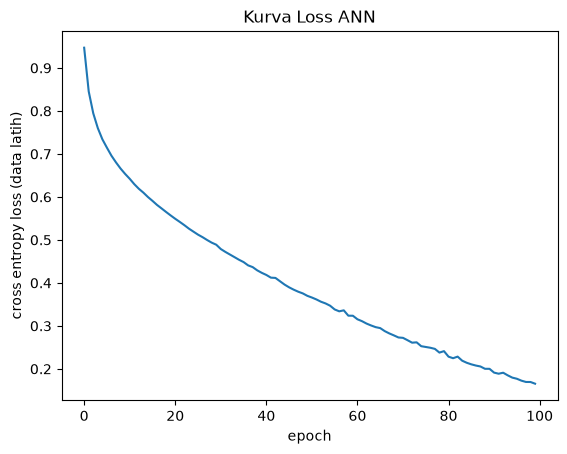

In [44]:
plt.plot(ann.loss_history)
plt.xlabel("epoch")
plt.ylabel("cross entropy loss (data latih)")
plt.title("Kurva Loss ANN")
plt.show()

In [45]:
hasil_epoch = []

for n_epoch in [10, 20, 30, 50, 100]:
    model = NeuralNetwork(hidden_layer_sizes=(64,32),activation="relu", learning_rate=0.01, batch_size=32, epochs=n_epoch, random_state=RANDOM_STATE)

    hasil = evaluasi(f"ANN epoch:{n_epoch}", model, X_fit, y_fit, X_v, y_v)
    hasil["macro F1 train"] = f1_score(y_fit, model.predict(X_fit), average="macro")

    hasil_epoch.append(hasil)

pd.DataFrame(hasil_epoch).round(3)

,model,accuracy,macro F1,durasi train,durasi inferensi,macro F1 train
0,ANN epoch:10,0.731,0.686,0.083,0.0,0.732
1,ANN epoch:20,0.756,0.715,0.162,0.0,0.777
2,ANN epoch:30,0.763,0.713,0.241,0.0,0.807
3,ANN epoch:50,0.752,0.698,0.444,0.0,0.870
4,ANN epoch:100,0.732,0.669,0.836,0.0,0.952


In [46]:
hasil_ann = []

for layer in[(32,), (64, 32), (128,64)]:
    for aktivasi in ["relu", "sigmoid"]:
        for n_epoch in [10, 20, 30, 50, 100, 200]:
            model = NeuralNetwork(hidden_layer_sizes=layer, activation=aktivasi, learning_rate=0.01, batch_size=32, epochs=n_epoch, random_state=RANDOM_STATE)
            hasil = evaluasi(f"ANN {layer} {aktivasi} epoch:{n_epoch}", model, X_fit, y_fit, X_v, y_v)
            hasil["macro F1 train"] = f1_score(y_fit, model.predict(X_fit), average="macro")

            hasil_ann.append(hasil)

pd.DataFrame(hasil_ann).sort_values("macro F1", ascending=False).head(10).round(3)

,model,accuracy,macro F1,durasi train,durasi inferensi,macro F1 train
35,"ANN (128, 64) sigmoid epoch:200",0.763,0.718,5.191,0.001,0.762
11,"ANN (32,) sigmoid epoch:200",0.760,0.717,1.447,0.000,0.768
13,"ANN (64, 32) relu epoch:20",0.756,0.715,0.199,0.000,0.777
22,"ANN (64, 32) sigmoid epoch:100",0.756,0.713,1.447,0.001,0.729
3,"ANN (32,) relu epoch:50",0.756,0.713,0.236,0.000,0.810
14,"ANN (64, 32) relu epoch:30",0.763,0.713,0.245,0.000,0.807
10,"ANN (32,) sigmoid epoch:100",0.755,0.711,0.711,0.000,0.748
23,"ANN (64, 32) sigmoid epoch:200",0.753,0.711,2.889,0.001,0.764
4,"ANN (32,) relu epoch:100",0.761,0.710,0.474,0.000,0.861
27,"ANN (128, 64) relu epoch:50",0.748,0.703,0.584,0.000,0.906


In [47]:
from sklearn.neural_network import MLPClassifier

ann = NeuralNetwork(hidden_layer_sizes=(64, 32), activation="relu", learning_rate=0.01, batch_size=32, epochs=20, random_state=RANDOM_STATE)
perbandingan.append(evaluasi("Implementasi ANN", ann, X_fit, y_fit, X_v, y_v))

ann_sklearn = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="sgd", learning_rate_init=0.01, batch_size=32, max_iter=20, momentum=0, alpha=0, random_state=RANDOM_STATE)
perbandingan.append(evaluasi("Sklearn ANN", ann_sklearn, X_fit, y_fit, X_v, y_v))

prediksi_sama = (ann.predict(X_v) == ann_sklearn.predict(X_v)).sum()
print("Jumlah Prediksi yang Sama: ", prediksi_sama, "Jumlah data: ", len(X_v))

pd.DataFrame(perbandingan).round(3)

Jumlah Prediksi yang Sama:  545 Jumlah data:  620


/Users/mekari/Documents/Code/python/Project-2-Advanced-AI/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,accuracy,macro F1,durasi train,durasi inferensi
0,Implementasi Decision Tree,0.715,0.690,1.089,0.002
1,Sklearn Decisison Tree,0.715,0.690,0.013,0.000
2,Implementasi Random Forest,0.782,0.740,25.639,0.365
3,Sklearn Random Forest,0.777,0.731,0.254,0.007
4,Implementasi ANN,0.756,0.715,0.162,0.000
5,Sklearn ANN,0.742,0.700,0.351,0.001


In [48]:
def detail_per_kelas(nama: str, model, X_val: np.ndarray, y_val: np.ndarray) -> None:
    prediksi = model.predict(X_val)
    kelas = np.unique(y_val)

    precision, recall, f1, jumlah = precision_recall_fscore_support(y_val, prediksi, labels=kelas)

    tabel = pd.DataFrame(
        {"precision": precision, "recall": recall, "f1": f1, "jumlah_val": jumlah},
        index=kelas,
    ).round(3)

    matriks = pd.DataFrame(
        confusion_matrix(y_val, prediksi, labels=kelas),
        index=[f"asli {k}" for k in kelas],
        columns=[f"prediksi {k}" for k in kelas],
    )

    print(nama)
    display(tabel)
    display(matriks)


model_final = [
    ("Implementasi Decision Tree", dt),
    ("Sklearn Decision Tree", dt_sklearn),
    ("Implementasi Random Forest", rf),
    ("Sklearn Random Forest", rf_sklearn),
    ("Implementasi ANN", ann),
    ("Sklearn ANN", ann_sklearn),
]

for nama, model in model_final:
    detail_per_kelas(nama, model, X_v, y_v)

Implementasi Decision Tree


,precision,recall,f1,jumlah_val
Dropout,0.930,0.603,0.732,199
Enrolled,0.410,0.775,0.536,111
Graduate,0.843,0.765,0.802,310


,prediksi Dropout,prediksi Enrolled,prediksi Graduate
asli Dropout,120,54,25
asli Enrolled,6,86,19
asli Graduate,3,70,237


Sklearn Decision Tree


,precision,recall,f1,jumlah_val
Dropout,0.930,0.603,0.732,199
Enrolled,0.410,0.775,0.536,111
Graduate,0.843,0.765,0.802,310


,prediksi Dropout,prediksi Enrolled,prediksi Graduate
asli Dropout,120,54,25
asli Enrolled,6,86,19
asli Graduate,3,70,237


... (8 outputs left out)

,prediksi Dropout,prediksi Enrolled,prediksi Graduate
asli Dropout,143,32,24
asli Enrolled,19,68,24
asli Graduate,6,46,258


Sklearn ANN


,precision,recall,f1,jumlah_val
Dropout,0.811,0.688,0.745,199
Enrolled,0.447,0.613,0.517,111
Graduate,0.853,0.823,0.837,310


,prediksi Dropout,prediksi Enrolled,prediksi Graduate
asli Dropout,137,39,23
asli Enrolled,22,68,21
asli Graduate,10,45,255
